Dataset loaded successfully!
Rows: 395
Columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guard

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Total missing values: 0
Duplicate rows: 0


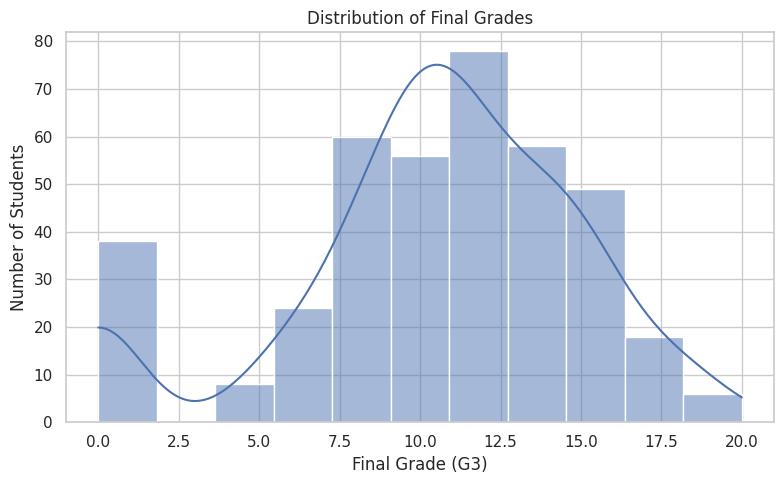

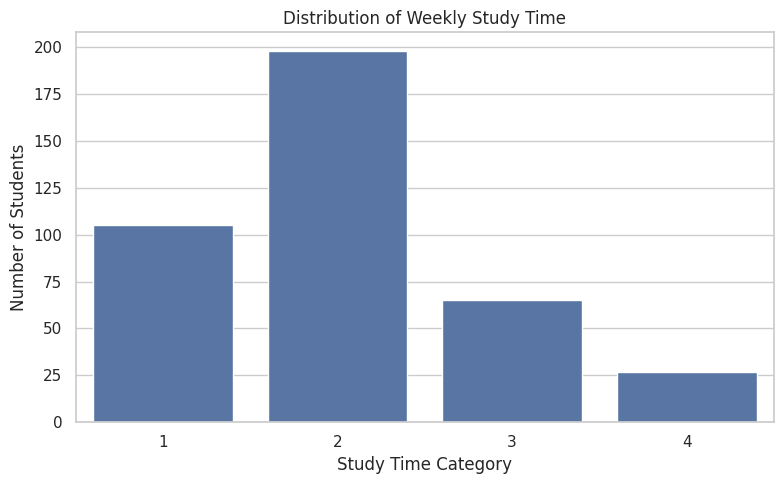

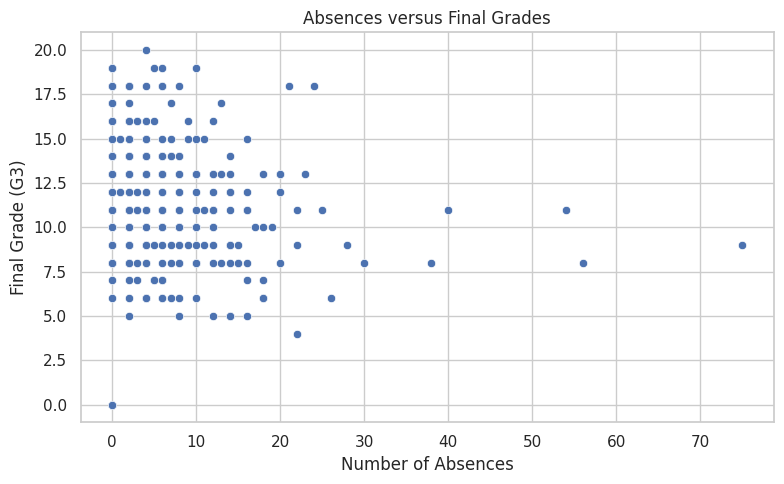

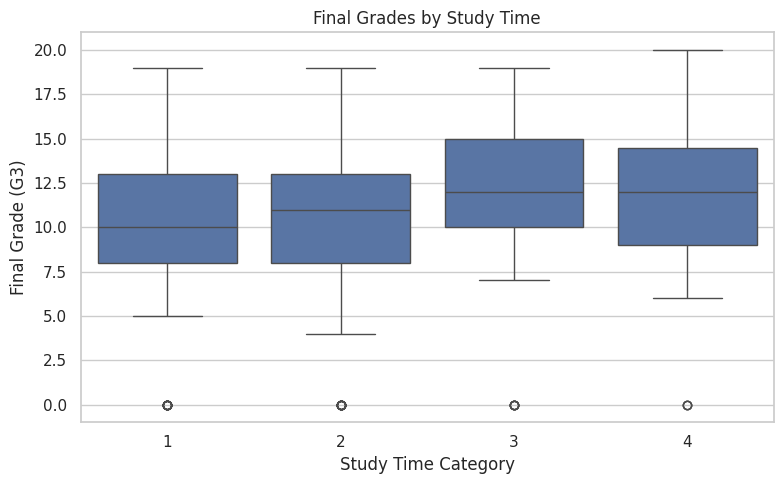

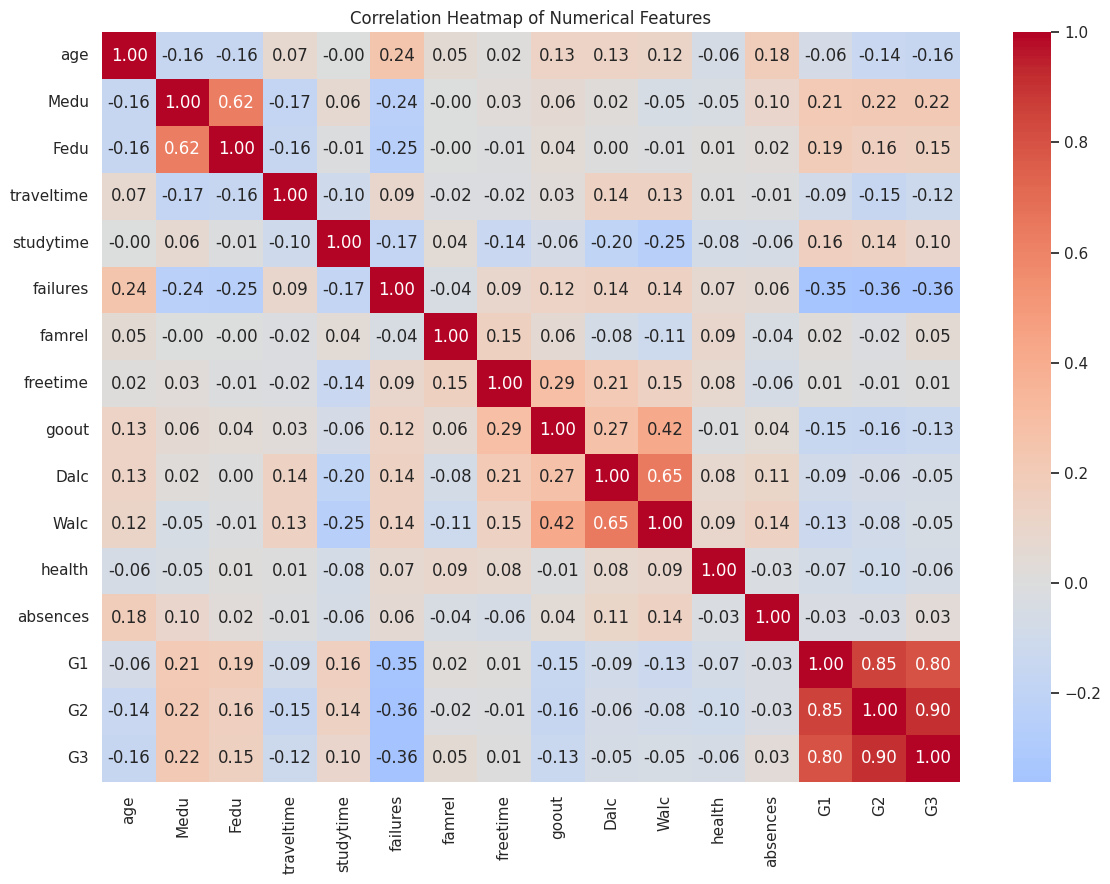


EDA completed successfully!


In [12]:

import io
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Download and load the dataset
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

try:
    request = urllib.request.Request(
        url, headers={"User-Agent": "Mozilla/5.0"}
    )
    with urllib.request.urlopen(request, timeout=30) as response:
        outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))

    if "student-mat.csv" in outer_zip.namelist():
        csv_data = outer_zip.read("student-mat.csv")
    else:
        nested_zip = zipfile.ZipFile(
            io.BytesIO(outer_zip.read("student.zip"))
        )
        csv_data = nested_zip.read("student-mat.csv")

    df = pd.read_csv(io.BytesIO(csv_data), sep=";")

except Exception as error:
    print("Primary download failed. Trying backup source...")
    backup_url = (
        "https://raw.githubusercontent.com/"
        "selva86/datasets/master/student-mat.csv"
    )
    df = pd.read_csv(backup_url, sep=";")

if "G3" not in df.columns or len(df) == 0:
    raise ValueError("Dataset loaded incorrectly. Please check the source.")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

# 2. Dataset information
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

# 3. Missing values and duplicates
print("\nMissing values:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# 4. Remove duplicate rows if any
df = df.drop_duplicates().copy()

# 5. Visualization 1: Final grade distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=11, kde=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# 6. Visualization 2: Study time distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="studytime")
plt.title("Distribution of Weekly Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# 7. Visualization 3: Absences versus final grades
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="absences", y="G3")
plt.title("Absences versus Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.tight_layout()
plt.show()

# 8. Visualization 4: Study time versus final grades
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Final Grades by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.tight_layout()
plt.show()

# 9. Visualization 5: Numerical correlation heatmap
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 9))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

print("\nEDA completed successfully!")


In [13]:

import pandas as pd
import numpy as np

numeric_df = df.select_dtypes(include="number")

stats = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Standard Deviation": numeric_df.std(),
    "Minimum": numeric_df.min(),
    "Maximum": numeric_df.max(),
    "Skewness": numeric_df.skew()
})

print("Statistical Analysis")
display(stats.round(2))


Statistical Analysis


,Mean,Median,Standard Deviation,Minimum,Maximum,Skewness
age,16.70,17.0,1.28,15,22,0.47
Medu,2.75,3.0,1.09,0,4,-0.32
Fedu,2.52,2.0,1.09,0,4,-0.03
traveltime,1.45,1.0,0.70,1,4,1.61
studytime,2.04,2.0,0.84,1,4,0.63
failures,0.33,0.0,0.74,0,3,2.39
famrel,3.94,4.0,0.90,1,5,-0.95
freetime,3.24,3.0,1.00,1,5,-0.16
goout,3.11,3.0,1.11,1,5,0.12
Dalc,1.48,1.0,0.89,1,5,2.19


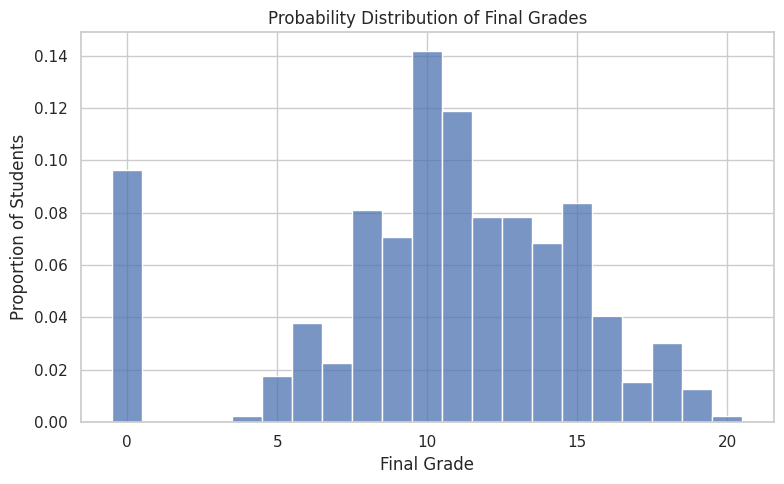

Probability of each final grade:


,Probability
G3,
0,0.0962
4,0.0025
5,0.0177
6,0.0380
7,0.0228
8,0.0810
9,0.0709
10,0.1418
11,0.1190


In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", discrete=True, stat="probability")
plt.title("Probability Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Proportion of Students")
plt.tight_layout()
plt.show()

grade_prob = df["G3"].value_counts(normalize=True).sort_index()
print("Probability of each final grade:")
display(grade_prob.rename("Probability").to_frame().round(4))


Lower bound: -12.0
Upper bound: 20.0
Potential absence outliers: 15


,absences,G1,G2,G3
40,25,7,10,11
74,54,11,12,11
103,26,7,6,6
183,56,9,9,8
198,24,18,18,18
205,28,10,9,9
216,22,6,6,4
260,21,17,18,18
276,75,10,9,9
277,22,9,9,9


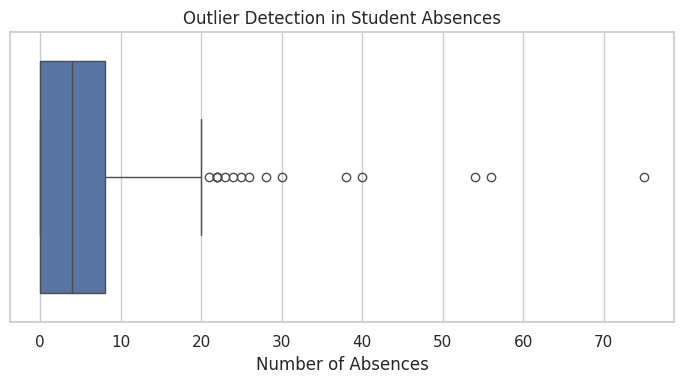

In [15]:

Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["absences"] < lower_bound) |
    (df["absences"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential absence outliers:", len(outliers))

display(outliers[["absences", "G1", "G2", "G3"]].head(10))

plt.figure(figsize=(7, 4))
sns.boxplot(x=df["absences"])
plt.title("Outlier Detection in Student Absences")
plt.xlabel("Number of Absences")
plt.tight_layout()
plt.show()


In [16]:

print("Missing values before cleaning:", df.isnull().sum().sum())
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Duplicate rows after cleaning:", df.duplicated().sum())


Missing values before cleaning: 0
Duplicate rows before cleaning: 0
Missing values after cleaning: 0
Duplicate rows after cleaning: 0


In [17]:

from sklearn.model_selection import train_test_split

df_model = df.copy()

y = (df_model["G3"] >= 10).astype(int)

X = df_model.drop(
    columns=["G1", "G2", "G3"]
)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTarget distribution:")
print(y.value_counts().rename(index={
    0: "Lower performance",
    1: "Higher performance"
}))


Training records: 276
Validation records: 59
Testing records: 60

Target distribution:
G3
Higher performance    265
Lower performance     130
Name: count, dtype: int64


In [18]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

X_train_processed = X_train_processed.astype("float32")
X_val_processed = X_val_processed.astype("float32")
X_test_processed = X_test_processed.astype("float32")

print("Training input shape:", X_train_processed.shape)
print("Validation input shape:", X_val_processed.shape)
print("Testing input shape:", X_test_processed.shape)
print("Preprocessing completed successfully!")


Training input shape: (276, 56)
Validation input shape: (59, 56)
Testing input shape: (60, 56)
Preprocessing completed successfully!


In [19]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

model.summary()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,761 (22.50 KB)

 Trainable params: 5,761 (22.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - accuracy: 0.6196 - auc: 0.5625 - loss: 0.6541 - val_accuracy: 0.6610 - val_auc: 0.5066 - val_loss: 0.6469
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6884 - auc: 0.5558 - loss: 0.6370 - val_accuracy: 0.6780 - val_auc: 0.5474 - val_loss: 0.6333
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7065 - auc: 0.6887 - loss: 0.5838 - val_accuracy: 0.6780 - val_auc: 0.5711 - val_loss: 0.6298
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7065 - auc: 0.6639 - loss: 0.5904 - val_accuracy: 0.6610 - val_auc: 0.5947 - val_loss: 0.6264
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7246 - auc: 0.7061 - loss: 0.5689 - val_accuracy: 0.6780 - val_auc: 0.6178 - val_loss: 0.6210
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.7391 - auc: 0.7229 - loss: 0.5584 - val_accuracy: 0.6780 - val_auc: 0.6322 - val_loss: 0.6147
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step -

In [20]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

y_prob = model.predict(X_test_processed, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Lower performance", "Higher performance"],
    zero_division=0
))


Test Accuracy: 0.6667
Test ROC-AUC: 0.6262

Classification Report:
                    precision    recall  f1-score   support

 Lower performance       0.50      0.35      0.41        20
Higher performance       0.72      0.82      0.77        40

          accuracy                           0.67        60
         macro avg       0.61      0.59      0.59        60
      weighted avg       0.64      0.67      0.65        60



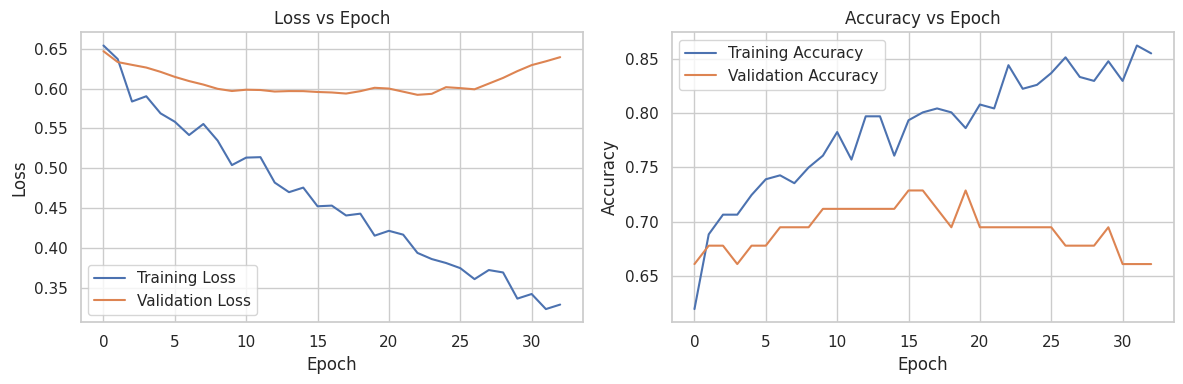

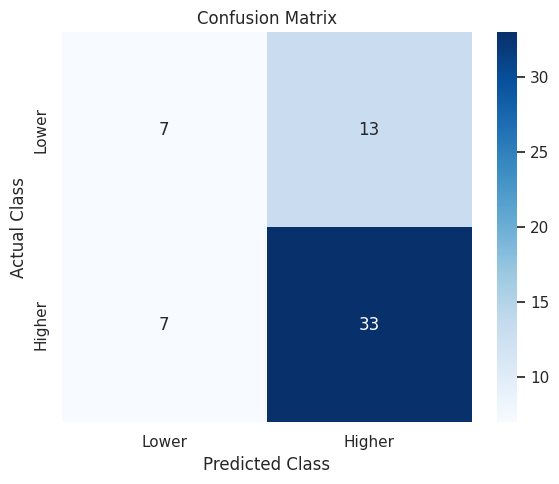

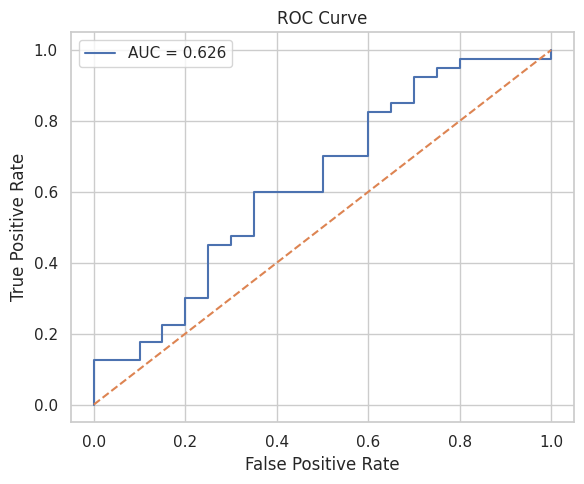

In [21]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Lower", "Higher"],
    yticklabels=["Lower", "Higher"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_value = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_value:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()


In [22]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})

display(results.round(4))


,Metric,Score
0,Accuracy,0.6667
1,Precision,0.7174
2,Recall,0.8250
3,F1-Score,0.7674
4,ROC-AUC,0.6262


,Feature,Importance
14,failures,0.0667
8,Mjob,0.0333
29,absences,0.0333
7,Fedu,0.0333
11,guardian,0.0167
12,traveltime,0.0167
16,famsup,0.0167
18,activities,0.0167
3,address,0.0000
21,internet,0.0000


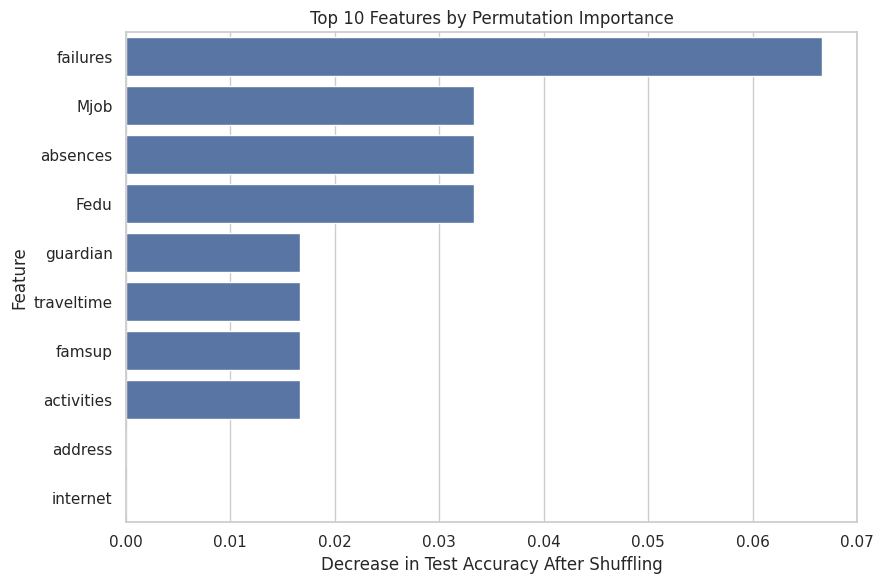

In [23]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

def model_accuracy(X_data):
    X_processed = preprocessor.transform(X_data).astype("float32")
    probabilities = model.predict(X_processed, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)
    return accuracy_score(y_test, predictions)

baseline_accuracy = model_accuracy(X_test)

importance_scores = []

for column in X_test.columns:
    shuffled = X_test.copy()
    shuffled[column] = np.random.RandomState(42).permutation(
        shuffled[column].values
    )
    shuffled_accuracy = model_accuracy(shuffled)

    importance_scores.append({
        "Feature": column,
        "Importance": baseline_accuracy - shuffled_accuracy
    })

importance_df = pd.DataFrame(importance_scores)
importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

display(importance_df.head(10).round(4))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Features by Permutation Importance")
plt.xlabel("Decrease in Test Accuracy After Shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


,Learning Rate,Validation Loss,Validation Accuracy
0,0.0001,0.6020,0.6949
1,0.0010,0.5615,0.7288
2,0.0100,0.5621,0.7288


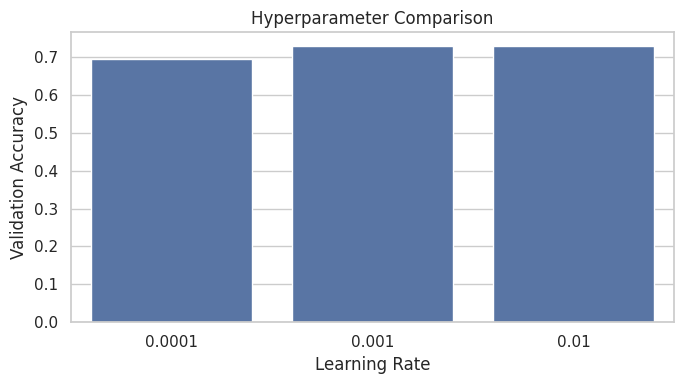

In [24]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tuning_results = []

for lr in [0.0001, 0.001, 0.01]:
    tf.keras.utils.set_random_seed(42)

    tuned_model = keras.Sequential([
        layers.Input(shape=(X_train_processed.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    tuned_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    tuned_model.fit(
        X_train_processed,
        y_train,
        validation_data=(X_val_processed, y_val),
        epochs=50,
        batch_size=32,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    val_loss, val_accuracy = tuned_model.evaluate(
        X_val_processed, y_val, verbose=0
    )

    tuning_results.append({
        "Learning Rate": lr,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df.round(4))

plt.figure(figsize=(7, 4))
sns.barplot(
    data=tuning_df,
    x="Learning Rate",
    y="Validation Accuracy"
)
plt.title("Hyperparameter Comparison")
plt.ylabel("Validation Accuracy")
plt.tight_layout()
plt.show()


In [25]:

import os
import json
import shutil

project_dir = "student_performance_project"
os.makedirs(project_dir, exist_ok=True)
os.makedirs(f"{project_dir}/visualizations", exist_ok=True)

# Save the cleaned dataset
df.to_csv(f"{project_dir}/student_performance_cleaned.csv", index=False)

# Save evaluation results
results.to_csv(f"{project_dir}/model_evaluation.csv", index=False)

# Save feature importance
importance_df.to_csv(
    f"{project_dir}/feature_importance.csv", index=False
)

# Save hyperparameter comparison
tuning_df.to_csv(
    f"{project_dir}/hyperparameter_tuning.csv", index=False
)

# Save the trained model
model.save(f"{project_dir}/student_performance_mlp.keras")

# Save preprocessing pipeline
import joblib
joblib.dump(
    preprocessor,
    f"{project_dir}/preprocessor.joblib"
)

# Save training history
with open(f"{project_dir}/training_history.json", "w") as file:
    json.dump(
        {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        },
        file,
        indent=2
    )

print("Project files saved successfully!")
print("Folder:", project_dir)
print("Files:", os.listdir(project_dir))


Project files saved successfully!
Folder: student_performance_project
Files: ['feature_importance.csv', 'model_evaluation.csv', 'student_performance_mlp.keras', 'visualizations', 'hyperparameter_tuning.csv', 'student_performance_cleaned.csv', 'training_history.json', 'preprocessor.joblib']


In [26]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "student_performance_project",
    "zip",
    root_dir="student_performance_project"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

print("========== MODEL EVALUATION ==========")
display(results)

print("\n========== HYPERPARAMETER TUNING ==========")
display(tuning_df)

print("\n========== TOP 10 IMPORTANT FEATURES ==========")
display(importance_df.head(10))

print("\n========== DATASET INFORMATION ==========")
print("Dataset shape:", df.shape)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Lower performance", "Higher performance"],
    zero_division=0
))


========== MODEL EVALUATION ==========


,Metric,Score
0,Accuracy,0.666667
1,Precision,0.717391
2,Recall,0.825000
3,F1-Score,0.767442
4,ROC-AUC,0.626250



========== HYPERPARAMETER TUNING ==========


,Learning Rate,Validation Loss,Validation Accuracy
0,0.0001,0.601963,0.694915
1,0.0010,0.561543,0.728814
2,0.0100,0.562093,0.728814



========== TOP 10 IMPORTANT FEATURES ==========


,Feature,Importance
14,failures,0.066667
8,Mjob,0.033333
29,absences,0.033333
7,Fedu,0.033333
11,guardian,0.016667
12,traveltime,0.016667
16,famsup,0.016667
18,activities,0.016667
3,address,0.000000
21,internet,0.000000



========== DATASET INFORMATION ==========
Dataset shape: (395, 33)
Training samples: 276
Validation samples: 59
Test samples: 60

========== CLASSIFICATION REPORT ==========
                    precision    recall  f1-score   support

 Lower performance       0.50      0.35      0.41        20
Higher performance       0.72      0.82      0.77        40

          accuracy                           0.67        60
         macro avg       0.61      0.59      0.59        60
      weighted avg       0.64      0.67      0.65        60

